# NB01b — Target transform comparison

**Input:** NB00's consolidated panels, through `container.panel_store()`.

**Output:** per target, a comparison table, a summary, a figure and a decision, logged to W&B (`nb01b-transforms-{variable}`); all tables in `nb01b_transform_comparison.csv`.

Closes the transform comparison the master plan lists for NB01 (O1), for the master plan's four targets like NB01. Spec: `docs/specs/transform-comparison.md`.

- **Revenue** is positive in every quarter: none, log, square root, Box-Cox with each company's λ and with its sector's λ. Baseline: **log**.
- **Operating income, EBITDA, free cash flow** are zero or negative in some quarters of 28 to 49 companies, where log, square root and Box-Cox are undefined. They are compared under transforms defined for signed values: none, the revenue-scaled value (the variable over its trailing four-quarter revenue), inverse hyperbolic sine, and Yeo-Johnson with each company's λ and with its sector's λ. Baseline: **revenue-scaled**, the transform their target arms use.

In [1]:
%matplotlib inline

In [2]:
import pandas as pd

from app.injections import configure_container
from app.services.diagnostics import (
    baseline_transform,
    candidates_for,
    preferred_transform,
    summarize_transforms,
)
from app.services.features import TargetVariable
from app.services.tracking import RunConfig, run_name

container = configure_container()
tracker = container.experiment_tracker()
comparer = container.transform_comparer()
eda_figures = container.eda_figures()
report_store = container.report_store()

# The forecast targets of master plan § 3.3, as in NB01.
TARGET_VARIABLES = [
    TargetVariable.REVENUE,
    TargetVariable.OPERATING_INCOME,
    TargetVariable.EBITDA,
    TargetVariable.FREE_CASH_FLOW,
]
NB00_COMPANIES = 60

panels = container.panel_store().load_consolidated()
assert len(panels) == NB00_COMPANIES

2026-10-20 09:59:51.236 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-20 09:59:51.236 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


## 1. Score every candidate

**Question:** For each target, under which transform does the size of its year-over-year change stop depending on the size of the company, and which leaves an STL remainder closest to normal?

Each company's series is prepared as in NB01 (spec T2). The *level dependence* is the absolute Spearman correlation between the company's 8-quarter mean revenue (its size) and the 8-quarter standard deviation of the transformed series' seasonal difference: near 0, the changes are the same size whatever the company's size (T3). The STL remainder is scored with Jarque–Bera, which decides, and Anderson–Darling, the second opinion (T4).

In [3]:
tables = {
    variable: comparer.compare(panels, variable=variable)
    for variable in TARGET_VARIABLES
}
for variable, table in tables.items():
    assert len(table) == table["ticker"].nunique() * len(candidates_for(variable))  # B1
assert tables[TargetVariable.REVENUE]["ticker"].nunique() == NB00_COMPANIES
summaries = {
    variable: summarize_transforms(table, baseline=baseline_transform(variable))
    for variable, table in tables.items()
}
pd.concat({variable.value: summary for variable, summary in summaries.items()}).round(3)

companies  level_dependence  \
                       transform                                         
revenue_usd_m          box_cox                    60             0.254   
                       box_cox_sector             60             0.288   
                       log                        60             0.312   
                       none                       60             0.432   
                       sqrt                       60             0.369   
operating_income_usd_m asinh                      59             0.281   
                       none                       59             0.404   
                       revenue_scaled             59             0.286   
                       yeo_johnson                59             0.343   
                       yeo_johnson_sector         59             0.398   
ebitda_usd_m           asinh                      59             0.293   
                       none                       59             0.397   
                       revenue_scaled             59             0.317   
                       yeo_johnson                59             0.373   
                       yeo_johnson_sector         59             0.364   
free_cash_flow_usd_m   asinh                      59             0.427   
                       none                       59             0.528   
                       revenue_scaled             59             0.363   
                       yeo_johnson                59             0.481   
                       yeo_johnson_sector         59             0.475   

                                           jarque_bera  anderson_darling  \
                       transform                                           
revenue_usd_m          box_cox                 144.684             7.880   
                       box_cox_sector          142.312             7.920   
                       log                     183.635             8.045   
                       none                    154.590             8.344   
                       sqrt                    155.493             8.150   
operating_income_usd_m asinh                   483.399            10.293   
                       none                    511.591            10.754   
                       revenue_scaled          512.305             9.974   
                       yeo_johnson             410.252             9.653   
                       yeo_johnson_sector      536.815            10.296   
ebitda_usd_m           asinh                   470.822            10.060   
                       none                    529.335            10.335   
                       revenue_scaled          372.318             9.125   
                       yeo_johnson             386.228             9.715   
                       yeo_johnson_sector      521.502            10.352   
free_cash_flow_usd_m   asinh                   203.235             7.190   
                       none                    227.838             7.981   
                       revenue_scaled          162.786             7.013   
                       yeo_johnson             170.601             7.012   
                       yeo_johnson_sector      243.647             7.845   

                                           abs_skewness  excess_kurtosis  \
                       transform                                           
revenue_usd_m          box_cox                    1.096            6.448   
                       box_cox_sector             1.102            6.386   
                       log                        1.151            6.913   
                       none                       1.216            6.463   
                       sqrt                       1.123            6.646   
operating_income_usd_m asinh                      2.249           11.292   
                       none                       2.306           11.203   
                       revenue_scaled             1.911  

## 2. Decision per target

**Rule (spec T6, fixed before the run):** each target keeps its baseline unless another transform beats it — lower level dependence *and* lower Jarque–Bera — in more than half of the companies. The decision is repeated with Anderson–Darling as the second opinion.

In [4]:
decisions = pd.DataFrame([
    {
        "target": variable.value,
        "baseline": baseline_transform(variable).value,
        "decision": preferred_transform(
            table, baseline=baseline_transform(variable)
        ).value,
        "decision_anderson_darling": preferred_transform(
            table, baseline=baseline_transform(variable), normality="anderson_darling"
        ).value,
        "best_challenger_share": summaries[variable]["beats_baseline_share"].max(),
        "best_challenger_share_ad": summaries[variable][
            "beats_baseline_share_ad"
        ].max(),
    }
    for variable, table in tables.items()
])
decisions.round(3)

,target,baseline,decision,decision_anderson_darling,best_challenger_share,best_challenger_share_ad
0,revenue_usd_m,log,log,log,0.400,0.433
1,operating_income_usd_m,revenue_scaled,revenue_scaled,revenue_scaled,0.288,0.288
2,ebitda_usd_m,revenue_scaled,revenue_scaled,revenue_scaled,0.254,0.288
3,free_cash_flow_usd_m,revenue_scaled,revenue_scaled,revenue_scaled,0.305,0.305


## 3. By sector

**Question:** Does any sector favour a different transform? Median level dependence per sector and transform.

In [5]:
by_sector = {
    variable: table.pivot_table(
        index="sector", columns="transform", values="level_dependence", aggfunc="median"
    )
    for variable, table in tables.items()
}
pd.concat({variable.value: table for variable, table in by_sector.items()}).round(2)

transform                                      box_cox  box_cox_sector   log  \
                       sector                                                  
revenue_usd_m          Communication Services     0.24            0.29  0.21   
                       Consumer Cyclical          0.37            0.52  0.54   
                       Consumer Defensive         0.39            0.28  0.30   
                       Energy                     0.12            0.16  0.28   
                       Healthcare                 0.25            0.27  0.20   
                       Industrials                0.25            0.41  0.38   
                       Materials                  0.26            0.32  0.31   
                       Technology                 0.14            0.14  0.25   
                       Utilities                  0.16            0.56  0.52   
operating_income_usd_m Communication Services      NaN             NaN   NaN   
                       Consumer Cyclical           NaN             NaN   NaN   
                       Consumer Defensive          NaN             NaN   NaN   
                       Energy                      NaN             NaN   NaN   
                       Healthcare                  NaN             NaN   NaN   
                       Industrials                 NaN             NaN   NaN   
                       Materials                   NaN             NaN   NaN   
                       Technology                  NaN             NaN   NaN   
                       Utilities                   NaN             NaN   NaN   
ebitda_usd_m           Communication Services      NaN             NaN   NaN   
                       Consumer Cyclical           NaN             NaN   NaN   
                       Consumer Defensive          NaN             NaN   NaN   
                       Energy                      NaN             NaN   NaN   
                       Healthcare                  NaN             NaN   NaN   
                       Industrials                 NaN             NaN   NaN   
                       Materials                   NaN             NaN   NaN   
                       Technology                  NaN             NaN   NaN   
                       Utilities                   NaN             NaN   NaN   
free_cash_flow_usd_m   Communication Services      NaN             NaN   NaN   
                       Consumer Cyclical           NaN             NaN   NaN   
                       Consumer Defensive          NaN             NaN   NaN   
                       Energy                      NaN             NaN   NaN   
                       Healthcare                  NaN             NaN   NaN   
                       Industrials                 NaN             NaN   NaN   
                       Materials                   NaN             NaN   NaN   
                       Technology                  NaN             NaN   NaN   
                       Utilities                   NaN             NaN   NaN   

transform                                      none  sqrt  asinh  \
                       sector                                      
revenue_usd_m          Communication Services  0.47  0.30    NaN   
                       Consumer Cyclical       0.53  0.54    NaN   
                       Consumer Defensive      0.28  0.20    NaN   
                       Energy                  0.32  0.17    NaN   
                       Healthcare              0.38  0.28    NaN   
                       Industrials             0.44  0.40    NaN   
                       Materials               0.26  0.24    NaN   
                       Technology              0.20  0.14    NaN   
                       Utilities               0.59  0.46    NaN   
operating_income_usd_m Communication Services  0.66   NaN   0.26   
                       Consumer Cyclical       0.64   NaN   0.62   
                       Consumer Defensive      0.38   NaN   0.28   
       

## 4. Figures and log

One W&B run per target, like NB01; every table also goes to `nb01b_transform_comparison.csv`.

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\leona\_netrc
wandb: Currently logged in as: leonardo-heis (leonardo-a-heis) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\leona\_netrc


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\leona\_netrc


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\leona\_netrc


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


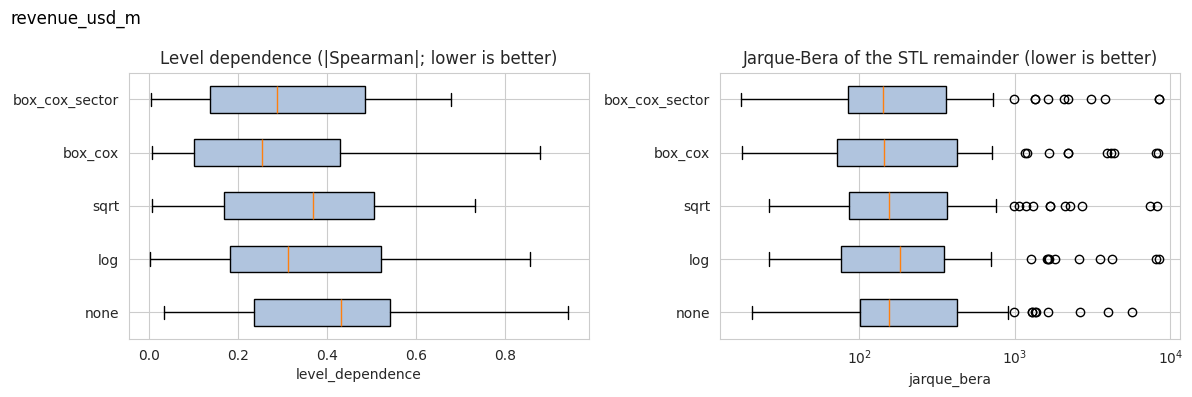

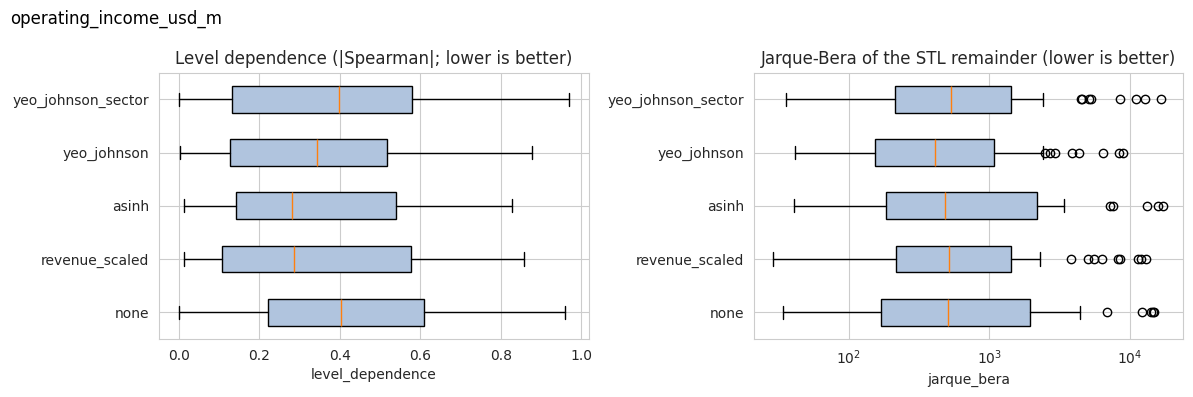

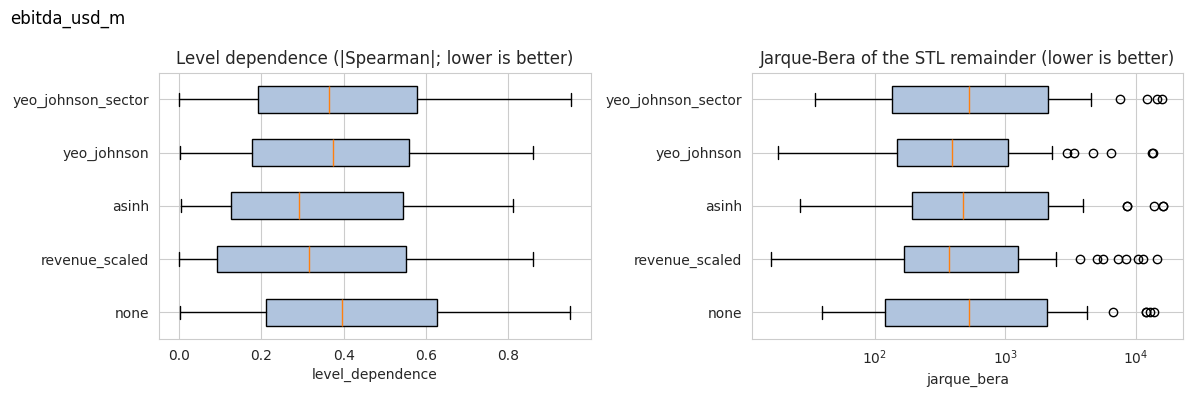

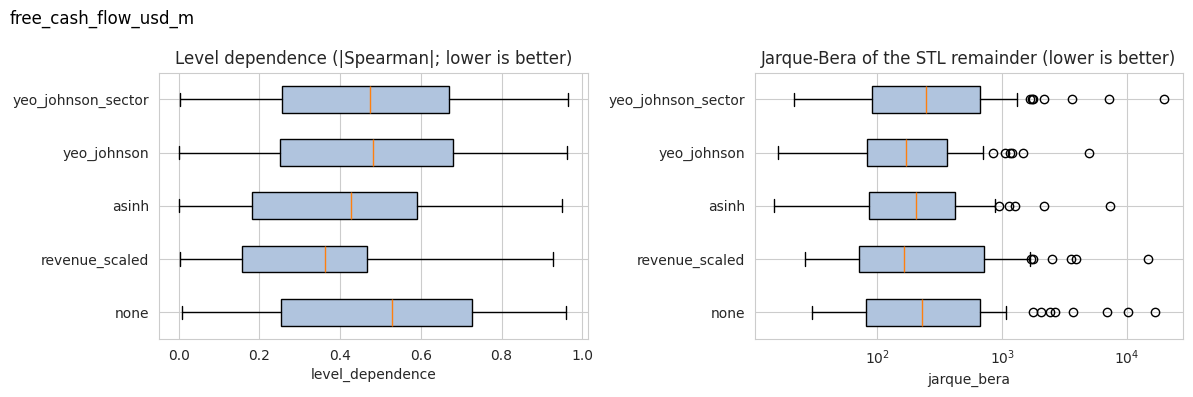

In [6]:
report_store.write_csv(pd.concat(tables.values()), "nb01b_transform_comparison.csv")
comparison_figures = {}
for variable, table in tables.items():
    comparison_figures[variable] = eda_figures.transform_comparison(table)
    comparison_figures[variable].suptitle(variable.value, x=0.01, ha="left")
    with tracker.start_run(
        run_name(notebook="nb01b", model="transforms", variable=variable.value),
        RunConfig(
            panel_size=len(panels),
            n_rows=len(table),
            target_variable=variable.value,
            target_transform=baseline_transform(variable).value,
        ),
        job_type="eda",
    ) as run:
        run.log_table("transform_comparison", table)
        run.log_table("transform_summary", summaries[variable].reset_index())
        run.log_table("level_dependence_by_sector", by_sector[variable].reset_index())
        run.log_table("decision", decisions.query("target == @variable.value"))
        run.log_figure("transform_comparison_boxplots", comparison_figures[variable])

**Answer** (run of 2026-10-13): **every target keeps the transform it uses today**, under Jarque–Bera and under the Anderson–Darling second opinion.

| Target | Baseline | Best challenger (beats the baseline in) | Decision |
|---|---|---|---|
| Revenue | log | sector Box-Cox (38%; 42% with Anderson–Darling) | log |
| Operating income | revenue-scaled | asinh (28%; Yeo-Johnson 30% with Anderson–Darling) | revenue-scaled |
| EBITDA | revenue-scaled | asinh (27%; Yeo-Johnson 30% with Anderson–Darling) | revenue-scaled |
| Free cash flow | revenue-scaled | Yeo-Johnson (33%; asinh 32% with Anderson–Darling) | revenue-scaled |

- **Revenue:** company Box-Cox has the lowest median level dependence (0.25), then sector Box-Cox (0.30), log (0.31), square root (0.37) and no transform (0.43). On normality the candidates are close; log is slightly the worst with Jarque–Bera (191 against 161–181) and in the middle with Anderson–Darling (8.14 against 7.96–8.38). No alternative is better on both criteria for most companies, and log is the only one that inverts exactly into the growth rates the target arms are built on, so log stays as the practical default, not because it wins.
- **Operating income:** the revenue-scaled value has the lowest level dependence (0.26; asinh 0.28, Yeo-Johnson 0.32, none 0.40). Yeo-Johnson leaves a more normal remainder (Jarque–Bera 423 against 493) but its changes depend more on size: a trade-off, not an improvement.
- **EBITDA:** the revenue-scaled value has the most normal remainder (Jarque–Bera 380, Anderson–Darling level with Yeo-Johnson at 9.66); asinh is slightly less size-dependent (0.29 against 0.31).
- **Free cash flow:** the revenue-scaled value is best on both criteria (level dependence 0.35, Jarque–Bera 157).
- **Normality:** no transform makes the remainder normal for any company in any target. Median excess kurtosis is about 7 for revenue and free cash flow and 10–12 for operating income and EBITDA. The heavy tails survive every transform, so they come from events (mergers, covid, impairments), not from scale: robust losses stay necessary (NB01 § 2).
- **By sector:** for revenue, company Box-Cox is much less size-dependent in Utilities (0.16 against 0.52 for log), Energy (0.12 against 0.28) and Technology (0.14 against 0.25); for free cash flow, the revenue-scaled value is far better in Communication Services (0.17 against 0.66–0.77). Utilities stay size-dependent for the signed targets under every transform (0.51–0.67). These sectors are candidates for a per-sector check of the target arms in the evaluation harness, not a reason to change the defaults.